## Idiosyncratic Volatility Evaluation in S&P500 Firms

#By Matheus M Wirth
#Seminar in Financial Econometrics

## 1. Setup 

In [4]:
pip install pandas yfinance lxml requests matplotlib statsmodels numpy scipy

Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
import numpy as np
import requests
from io import StringIO, BytesIO
from scipy import signal
import zipfile
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")
import matplotlib.patches as mpatches
from scipy import stats
import yfinance as yf
import os

pd.set_option("display.max_columns", 20)

## 2. Download ticker symbols for all firms

In [7]:
TICKER_CACHE_PATH = "sp500_constituents_cache.csv"
TICKER_SNAPSHOT_DATE = "2026-07-10"  # record when you pulled this

if os.path.exists(TICKER_CACHE_PATH):
    sp500_table = pd.read_csv(TICKER_CACHE_PATH)
    print(f"Loaded cached S&P 500 constituent list from {TICKER_SNAPSHOT_DATE} ({len(sp500_table)} firms)")
else:
    url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    response = requests.get(url, headers=headers)
    sp500_table = pd.read_html(StringIO(response.text))[0]
    sp500_table.to_csv(TICKER_CACHE_PATH, index=False)
    print(f"Downloaded and cached S&P 500 constituent list ({len(sp500_table)} firms)")

tickers = sp500_table["Symbol"].tolist()
tickers = [t.replace(".", "-") for t in tickers]

sector_map = sp500_table.set_index("Symbol")["GICS Sector"]
sector_map.index = [t.replace(".", "-") for t in sector_map.index]
subindustry_map = sp500_table.set_index("Symbol")["GICS Sub-Industry"]
subindustry_map.index = [t.replace(".", "-") for t in subindustry_map.index]

print(f"Number of companies: {len(tickers)}")
print(f"Number of GICS sectors: {sector_map.nunique()}")
sector_map.value_counts()

Downloaded and cached S&P 500 constituent list (503 firms)
Number of companies: 503
Number of GICS sectors: 11


GICS Sector
Industrials               81
Financials                76
Information Technology    74
Health Care               59
Consumer Discretionary    47
Consumer Staples          34
Utilities                 31
Real Estate               31
Materials                 26
Communication Services    23
Energy                    21
Name: count, dtype: int64

## 3. Download historical daily prices

In [9]:
END_DATE = "2026-06-18"  # fixed sample end — keep this pinned so the panel is reproducible

prices = yf.download(
    tickers,
    start="2015-01-01",   # window choice explained in Section 3
    end=END_DATE,
    auto_adjust=True,
    progress=True,
)
close_prices = prices["Close"]
close_prices.shape

[*********************100%***********************]  503 of 503 completed


(2881, 503)

## 4. Defining the sample window

In [11]:
# 5% of missing data filter

missing_frac = close_prices.isna().mean()
keep_tickers = missing_frac[missing_frac <= 0.05].index.tolist()
print(f"Keeping {len(keep_tickers)} of {close_prices.shape[1]} tickers with <=5% missing data")

close_prices = close_prices[keep_tickers].dropna(how="all")
close_prices = close_prices.ffill().dropna(how="all")
close_prices = close_prices.dropna(axis=1)   # final balanced panel: no remaining NaNs

print(f"Final balanced panel: {close_prices.shape[0]} days x {close_prices.shape[1]} firms")
print(f"Window: {close_prices.index.min().date()} to {close_prices.index.max().date()}")


Keeping 464 of 503 tickers with <=5% missing data
Final balanced panel: 2881 days x 460 firms
Window: 2015-01-02 to 2026-06-17


## 5. Estimating daily excess returns - following Campbell, et al. (2001)

In [13]:
#It is also used the 3-Month T-bill rate

rets = close_prices.pct_change().dropna(how="all")

rf_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3"
rf_raw = pd.read_csv(rf_url, na_values=".")

# FRED's export sometimes calls the date column "DATE", sometimes "observation_date" --
# grab whichever is first instead of hardcoding the name, so this doesn't break again.
date_col = rf_raw.columns[0]
rf_raw[date_col] = pd.to_datetime(rf_raw[date_col])
rf_raw = rf_raw.set_index(date_col)["DTB3"].astype(float)

rf_raw = rf_raw.reindex(rets.index).ffill() / 100.0       # annualized decimal yield

rf_daily = rf_raw / 252.0
excess_rets = rets.sub(rf_daily, axis=0).dropna(how="all")
print(excess_rets.shape)
excess_rets.head()


(2880, 460)


Ticker,A,AAPL,ABBV,ABT,ACGL,ACN,ADBE,ADI,ADM,ADP,...,WTW,WY,WYNN,XEL,XOM,XYL,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-05,-0.018739,-0.028173,-0.018820,0.000221,-0.005985,-0.016886,-0.004978,-0.018186,-0.034603,-0.000722,...,-0.007184,-0.000001,-0.017021,-0.011352,-0.027363,-0.062239,-0.020319,0.037302,-0.014078,-0.006004
2015-01-06,-0.015579,0.000093,-0.004951,-0.011357,0.002235,-0.007214,-0.020146,-0.023474,-0.019714,-0.008292,...,-0.004975,-0.001109,-0.021332,0.005320,-0.005317,-0.005882,-0.012276,-0.008478,-0.007206,-0.009758
2015-01-07,0.013271,0.014021,0.040415,0.008107,0.005834,0.020988,0.008222,0.010515,0.015030,0.008722,...,0.014313,0.003048,0.029367,0.008633,0.010131,0.007886,0.033137,0.024869,0.025464,0.020642
2015-01-08,0.029974,0.038421,0.010458,0.020553,0.017402,0.015248,0.025452,0.017653,-0.014610,0.022939,...,0.011424,0.010778,0.012030,0.011598,0.016644,0.007545,0.017419,0.010616,0.021357,0.015397
2015-01-09,-0.007338,0.001072,-0.027356,-0.010509,-0.008721,-0.001113,-0.014812,-0.000731,-0.008530,-0.007163,...,-0.008860,-0.001368,0.012499,-0.012286,-0.001411,-0.018864,-0.001767,-0.014425,0.014613,0.001584


## 6. Estimating cap weights

In [15]:
import time

MCAP_CACHE_PATH = "market_cap_cache.csv"
MCAP_SNAPSHOT_DATE = "2026-07-10"  # record when you pulled this

if os.path.exists(MCAP_CACHE_PATH):
    mcap = pd.read_csv(MCAP_CACHE_PATH, index_col=0).squeeze("columns")
    mcap = mcap.reindex(close_prices.columns)
    print(f"Loaded cached market caps from {MCAP_SNAPSHOT_DATE} ({mcap.notna().sum()} of {len(mcap)} firms)")
else:
    mcaps = {}
    failed = []

    for t in close_prices.columns:
        val = np.nan
        try:
            fi = yf.Ticker(t).fast_info
            val = fi.get("marketCap", fi.get("market_cap", np.nan))
        except Exception:
            pass

        if val is None or (isinstance(val, float) and np.isnan(val)):
            try:
                val = yf.Ticker(t).info.get("marketCap", np.nan)
            except Exception:
                val = np.nan

        mcaps[t] = val
        if val is None or (isinstance(val, float) and np.isnan(val)):
            failed.append(t)

        time.sleep(0.05)

    print(f"Failed to get market cap for {len(failed)} tickers: {failed[:15]}{'...' if len(failed) > 15 else ''}")
    mcap = pd.Series(mcaps).reindex(close_prices.columns)
    mcap.to_csv(MCAP_CACHE_PATH)
    print(f"Downloaded and cached market caps ({mcap.notna().sum()} of {len(mcap)} firms)")

mcap = mcap.fillna(mcap.median())
w_vw = mcap / mcap.sum()
w_ew = pd.Series(1.0 / len(mcap), index=mcap.index)

print(w_vw.sort_values(ascending=False).head(10))

Failed to get market cap for 0 tickers: []
Downloaded and cached market caps (460 of 460 firms)
Ticker
NVDA     0.070406
AAPL     0.066577
GOOGL    0.062778
GOOG     0.062314
MSFT     0.040929
AMZN     0.038094
AVGO     0.027355
META     0.022978
TSLA     0.021888
MU       0.016054
dtype: float64


In [16]:
#Robustness check
print(w_vw.sum())
print(mcap.isna().sum())
print(w_vw.sort_values(ascending=False).head(10).sum())

1.0
0
0.4293728615761764


## 7. Replication exercise

## 7.1 Volatility decomposition

In [19]:
def industry_returns(excess_rets, sector_map, w_vw):
    """Compute value-weighted industry (GICS sector) excess returns for each day."""
    sectors = sector_map.reindex(excess_rets.columns)
    ind_ret = pd.DataFrame(index=excess_rets.index)

    for sec in sectors.unique():
        members = sectors[sectors == sec].index.intersection(excess_rets.columns)
        w_sec = w_vw[members] / w_vw[members].sum()
        ind_ret[sec] = (excess_rets[members] * w_sec).sum(axis=1)

    return ind_ret, sectors

ind_ret, sectors = industry_returns(excess_rets, sector_map, w_vw)

# Market return: weighted average across firms (eq. before eq 1)
mkt_ret = (excess_rets * w_vw).sum(axis=1)

# eps_it = R_it - R_mt   (eq. 6), one column per GICS sector
eps = ind_ret.sub(mkt_ret, axis=0)

# eta_jit = R_jit - R_it (eq. 10), one column per firm, using its own sector's return
firm_industry_ret = pd.DataFrame({t: ind_ret[sectors[t]] for t in excess_rets.columns})
eta = excess_rets - firm_industry_ret

print("eps shape (days x sectors):", eps.shape)
print("eta shape (days x firms):  ", eta.shape)


eps shape (days x sectors): (2880, 11)
eta shape (days x firms):   (2880, 460)


In [20]:
def monthly_volatility_components(mkt_ret, eps, eta, w_vw, sectors):
    """
    Build monthly MKT, IND, FIRM series following CLMX eq. (17)-(22).
    MKT_t  = sum over days in month t of (R_ms - mean(R_m))^2
    IND_t  = weighted average over sectors of sum_s eps_is^2 within month t
    FIRM_t = weighted average (sector, then firm) of sum_s eta_js^2 within month t
    All annualized by multiplying by 12.
    """
    months = mkt_ret.index.to_period("M")

    mu_m = mkt_ret.mean()  # CLMX use the full-sample mean (footnote 3); time-varying mean gives similar results
    mkt_monthly = ((mkt_ret - mu_m) ** 2).groupby(months).sum() * 12

    # industry weight = share of market cap held by that sector
    sector_weight = w_vw.groupby(sectors.reindex(w_vw.index)).sum()

    eps_sq_monthly = (eps ** 2).groupby(months).sum()          # sum_s eps_is^2 per sector per month
    ind_monthly = (eps_sq_monthly * sector_weight).sum(axis=1) * 12

    eta_sq_monthly = (eta ** 2).groupby(months).sum()          # sum_s eta_js^2 per firm per month
    firm_monthly = (eta_sq_monthly * w_vw).sum(axis=1) * 12

    out = pd.DataFrame({"MKT": mkt_monthly, "IND": ind_monthly, "FIRM": firm_monthly})
    out.index = out.index.to_timestamp()
    return out

vol_components = monthly_volatility_components(mkt_ret, eps, eta, w_vw, sectors)
vol_components.describe()


,MKT,IND,FIRM
count,138.000000,138.000000,138.000000
mean,0.042114,0.020127,0.052456
std,0.087708,0.012126,0.026489
min,0.004215,0.005151,0.020105
25%,0.013039,0.011021,0.035642
50%,0.022713,0.017668,0.046563
75%,0.043111,0.025434,0.064387
max,0.962190,0.094481,0.252797


In [21]:
from statsmodels.tsa.stattools import adfuller

for col in ["MKT", "IND", "FIRM"]:
    result = adfuller(vol_components[col].dropna())

    print(f"\n===== {col} =====")
    print(f"ADF statistic : {result[0]:.4f}")
    print(f"p-value       : {result[1]:.4f}")
    print(f"Lags used     : {result[2]}")
    print(f"Observations  : {result[3]}")

    print("Critical values:")
    for key, value in result[4].items():
        print(f"  {key}: {value:.4f}")

    if result[1] < 0.05:
        print("→ Reject H0: series is stationary.")
    else:
        print("→ Fail to reject H0: series may contain a unit root.")


===== MKT =====
ADF statistic : -9.0002
p-value       : 0.0000
Lags used     : 0
Observations  : 137
Critical values:
  1%: -3.4790
  5%: -2.8829
  10%: -2.5781
→ Reject H0: series is stationary.

===== IND =====
ADF statistic : -7.1590
p-value       : 0.0000
Lags used     : 0
Observations  : 137
Critical values:
  1%: -3.4790
  5%: -2.8829
  10%: -2.5781
→ Reject H0: series is stationary.

===== FIRM =====
ADF statistic : -7.6646
p-value       : 0.0000
Lags used     : 0
Observations  : 137
Critical values:
  1%: -3.4790
  5%: -2.8829
  10%: -2.5781
→ Reject H0: series is stationary.


In [22]:
def volatility_summary_table(vol_components):
    """
    Summary table of average volatility (in variance and standard-deviation terms)
    for MKT, IND, and FIRM components.

    Average volatility = sqrt(mean of the monthly variance series),
    NOT the mean of monthly sqrt(variance) — these differ due to Jensen's inequality.
    """
    mean_var = vol_components.mean()                 # average variance per component
    avg_vol  = np.sqrt(mean_var)                      # sqrt(mean variance) -- correct measure

    # For comparison / transparency: the (incorrect) mean-of-sqrt alternative
    mean_of_sqrt = np.sqrt(vol_components).mean()

    summary = pd.DataFrame({
        "Mean Variance":               mean_var,
        "Avg. Volatility (sqrt of mean var)": avg_vol,
        "Mean of sqrt(var) [for reference only]": mean_of_sqrt,
    })

    summary["Share of Total Variance"] = mean_var / mean_var.sum()

    return summary

vol_summary = volatility_summary_table(vol_components)
vol_summary

,Mean Variance,Avg. Volatility (sqrt of mean var),Mean of sqrt(var) [for reference only],Share of Total Variance
MKT,0.042114,0.205217,0.176121,0.367175
IND,0.020127,0.141871,0.136544,0.175482
FIRM,0.052456,0.229034,0.223608,0.457343


In [23]:
vol_components["MKT"].idxmax()

Timestamp('2020-03-01 00:00:00')

In [24]:
#Finding volatility components

shares = vol_components.div(vol_components.sum(axis=1), axis=0).mean()
print(shares)

MKT     0.293353
IND     0.187013
FIRM    0.519634
dtype: float64


In [25]:
#Sector classification of firms (GICS)
sectors.value_counts()

GICS Sector
Financials                72
Industrials               70
Information Technology    64
Health Care               56
Consumer Discretionary    44
Consumer Staples          32
Utilities                 29
Real Estate               29
Materials                 24
Energy                    20
Communication Services    20
Name: count, dtype: int64

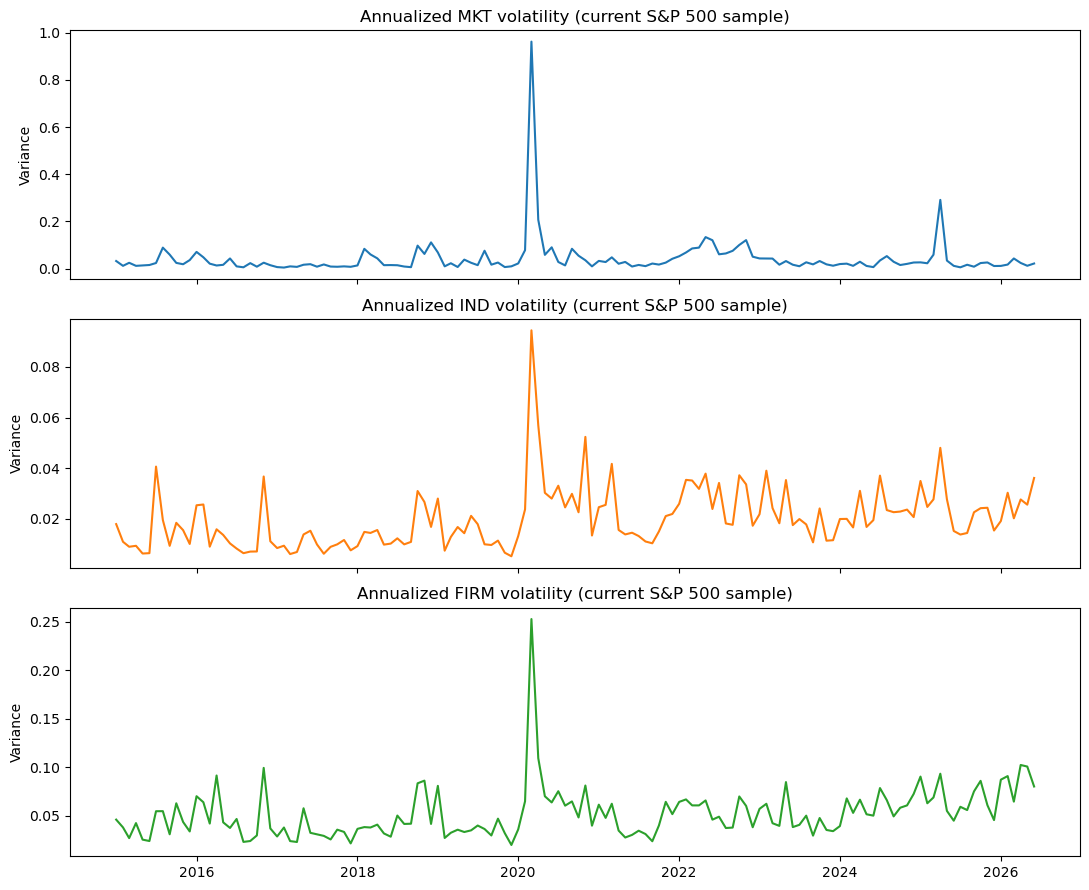

In [140]:
#Volatility components graph

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, col, color in zip(axes, ["MKT", "IND", "FIRM"], ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(vol_components.index, vol_components[col], color=color)
    ax.set_title(f"Annualized {col} volatility (current S&P 500 sample)")
    ax.set_ylabel("Variance")
plt.tight_layout()
plt.savefig("vol_series.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
#Finding volatility components share

total = vol_components.sum(axis=1)
shares = vol_components.div(total, axis=0).mean()
print("Average share of total volatility, 2015-present sample:")
print(shares)
print()

Average share of total volatility, 2015-present sample:
MKT     0.293353
IND     0.187013
FIRM    0.519634
dtype: float64



## 7.1 Robustness check with Fama-French market and industry volatility

In [29]:
def download_ff_csv(url, skiprows, nrows=None):
    """Download and unzip a Ken French data file, return as DataFrame indexed by date.
    Handles files (like the 49-industry one) that stack multiple tables (value-weighted,
    then equal-weighted) in a single CSV by stopping at the first non-numeric date row."""
    r = requests.get(url, timeout=60)
    z = zipfile.ZipFile(BytesIO(r.content))
    fname = z.namelist()[0]
    raw = z.read(fname).decode("latin-1")

    df = pd.read_csv(StringIO(raw), skiprows=skiprows, nrows=nrows)
    df = df.rename(columns={df.columns[0]: "Date"})

    # Find where the first table ends: the row where "Date" stops being a valid yyyymmdd number
    date_numeric = pd.to_numeric(df["Date"], errors="coerce")
    first_invalid = date_numeric.isna().idxmax() if date_numeric.isna().any() else len(df)
    df = df.iloc[:first_invalid]

    df["Date"] = pd.to_datetime(df["Date"], format="%Y%m%d")
    df = df.set_index("Date")
    df = df[~df.index.duplicated(keep="first")]   # safety net
    return df.apply(pd.to_numeric, errors="coerce") / 100.0

In [30]:
#Download Fama-French library

def download_ff_csv(url, skiprows):
    """
    Download and parse a Ken French data library CSV file.
    
    Parameters
    ----------
    url      : URL of the zip file on Ken French's website
    skiprows : number of header rows to skip before the data starts
               (varies by file — check manually if results look wrong)
    
    Returns
    -------
    DataFrame indexed by date (daily frequency), values in decimal
    (already divided by 100 to convert from percentage)
    """
    print(f"Downloading: {url.split('/')[-1]}")
    
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    
    z     = zipfile.ZipFile(BytesIO(r.content))
    fname = z.namelist()[0]
    raw   = z.read(fname).decode("latin-1")
    
    # Read raw CSV, skipping file-level headers
    df = pd.read_csv(StringIO(raw), skiprows=skiprows)
    df = df.rename(columns={df.columns[0]: "Date"})
    
   
    date_numeric  = pd.to_numeric(df["Date"], errors="coerce")
    first_invalid = date_numeric.isna().idxmax() \
                    if date_numeric.isna().any() else len(df)
    df = df.iloc[:first_invalid].copy()
    
    df["Date"] = pd.to_datetime(df["Date"].astype(str), format="%Y%m%d")
    df = df.set_index("Date")
    
    df = df[~df.index.duplicated(keep="first")]

    return df.apply(pd.to_numeric, errors="coerce") / 100.0


# Download datasets

FF3_URL  = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/"
            "ftp/F-F_Research_Data_Factors_daily_CSV.zip")

FF49_URL = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/"
            "ftp/49_Industry_Portfolios_daily_CSV.zip")

try:
    ff3  = download_ff_csv(FF3_URL,  skiprows=4)
    print(f"FF3  downloaded:  {ff3.shape[0]:,} daily obs, "
          f"columns = {ff3.columns.tolist()}")
except Exception as e:
    print(f"FF3 download failed: {e}")
    ff3 = None

try:
    ff49 = download_ff_csv(FF49_URL, skiprows=11)
    print(f"FF49 downloaded: {ff49.shape[0]:,} daily obs, "
          f"{ff49.shape[1]} industries")
except Exception as e:
    print(f"FF49 download failed: {e}")
    ff49 = None

Downloading: F-F_Research_Data_Factors_daily_CSV.zip
FF3  downloaded:  26,253 daily obs, columns = ['Mkt-RF', 'SMB', 'HML', 'RF']
Downloading: 49_Industry_Portfolios_daily_CSV.zip
FF49 downloaded: 26,251 daily obs, 49 industries


In [31]:
#Robustness check of downloads before using them (to avoid mistakes)

if ff3 is not None:
    print("=== FF3 sample (first 3 rows) ===")
    print(ff3.head(3))
    print(f"\nDate range: {ff3.index.min().date()} "
          f"to {ff3.index.max().date()}")
    print(f"Duplicates: {ff3.index.duplicated().sum()}")
    print(f"Any NaN in Mkt-RF: {ff3['Mkt-RF'].isna().sum()}")
    print()

if ff49 is not None:
    print("=== FF49 sample (first 3 rows, first 5 columns) ===")
    print(ff49.iloc[:3, :5])
    print(f"\nDate range: {ff49.index.min().date()} "
          f"to {ff49.index.max().date()}")
    print(f"Duplicates: {ff49.index.duplicated().sum()}")
    
    # French uses -99.99 or -999 as missing value codes
    # These need to be replaced with NaN
    missing_codes = [-99.99, -999.0, -99.990]
    n_missing_before = ff49.isna().sum().sum()
    ff49 = ff49.replace(missing_codes, np.nan)
    n_missing_after = ff49.isna().sum().sum()
    print(f"Missing value codes replaced: "
          f"{n_missing_after - n_missing_before} cells set to NaN")

=== FF3 sample (first 3 rows) ===
            Mkt-RF     SMB     HML      RF
Date                                      
1926-07-01  0.0009 -0.0025 -0.0027  0.0001
1926-07-02  0.0045 -0.0033 -0.0006  0.0001
1926-07-06  0.0017  0.0030 -0.0039  0.0001

Date range: 1926-07-01 to 2026-05-29
Duplicates: 0
Any NaN in Mkt-RF: 0

=== FF49 sample (first 3 rows, first 5 columns) ===
              0.29    0.06  -99.99    0.78    0.70
Date                                              
1926-07-06 -0.0033  0.0018 -0.9999 -0.0174  0.0050
1926-07-07  0.0357 -0.0015 -0.9999 -0.0173 -0.0012
1926-07-08  0.0030  0.0112 -0.9999 -0.0015  0.0030

Date range: 1926-07-06 to 2026-05-29
Duplicates: 0
Missing value codes replaced: 0 cells set to NaN


In [32]:
#Restrict both datasets to my study window (2015-2026)

STUDY_START = "2015-01-01"
STUDY_END   = "2026-12-31"

if ff3 is not None:
    ff3 = ff3.loc[STUDY_START:STUDY_END]
    print(f"FF3  restricted to study window: {len(ff3):,} daily obs")

if ff49 is not None:
    ff49 = ff49.loc[STUDY_START:STUDY_END]
    print(f"FF49 restricted to study window: {len(ff49):,} daily obs")

FF3  restricted to study window: 2,868 daily obs
FF49 restricted to study window: 2,868 daily obs


In [33]:
#Correlation matrix of S&P500 with Fama-French library

if ff3 is None or ff49 is None:
    print("ERROR: ff3 or ff49 failed to download. "
          "Check your internet connection and rerun Step 2.")
else:

    common_dates  = ff3.index.intersection(ff49.index)
    ff3_aligned   = ff3.loc[common_dates]
    ff49_aligned  = ff49.loc[common_dates]
    
    print(f"Common dates between FF3 and FF49: {len(common_dates):,}")
    print(f"Overlap with your study window: "
          f"{common_dates.min().date()} to {common_dates.max().date()}")
    
    months = common_dates.to_period("M")
    
    ff_mkt_monthly = (ff3_aligned["Mkt-RF"] ** 2)\
                     .groupby(months).sum() * 12
    
    ff49_eps       = ff49_aligned.sub(ff3_aligned["Mkt-RF"], axis=0)
    ff_ind_monthly = (ff49_eps ** 2)\
                     .groupby(months).sum()\
                     .mean(axis=1) * 12
    
    ff_compare = pd.DataFrame({
        "MKT_FF": ff_mkt_monthly,
        "IND_FF": ff_ind_monthly,
    })
    ff_compare.index = ff_compare.index.to_timestamp()
    
    ff_compare = ff_compare.dropna()
    
    print(f"\nFF benchmark series: {len(ff_compare)} monthly observations")
    print(f"Window: {ff_compare.index.min().date()} "
          f"to {ff_compare.index.max().date()}")
    
    # Join with my own MKT/IND series
    compare = vol_components[["MKT", "IND"]].join(
        ff_compare, how="inner"
    )
    
    print(f"\nJoined comparison dataset: {len(compare)} common months")
    print(f"\n=== Correlation matrix ===")
    print(compare.corr().round(4))

Common dates between FF3 and FF49: 2,868
Overlap with your study window: 2015-01-02 to 2026-05-29

FF benchmark series: 137 monthly observations
Window: 2015-01-01 to 2026-05-01

Joined comparison dataset: 137 common months

=== Correlation matrix ===
           MKT     IND  MKT_FF  IND_FF
MKT     1.0000  0.6980  0.9972  0.8142
IND     0.6980  1.0000  0.6838  0.8641
MKT_FF  0.9972  0.6838  1.0000  0.8186
IND_FF  0.8142  0.8641  0.8186  1.0000


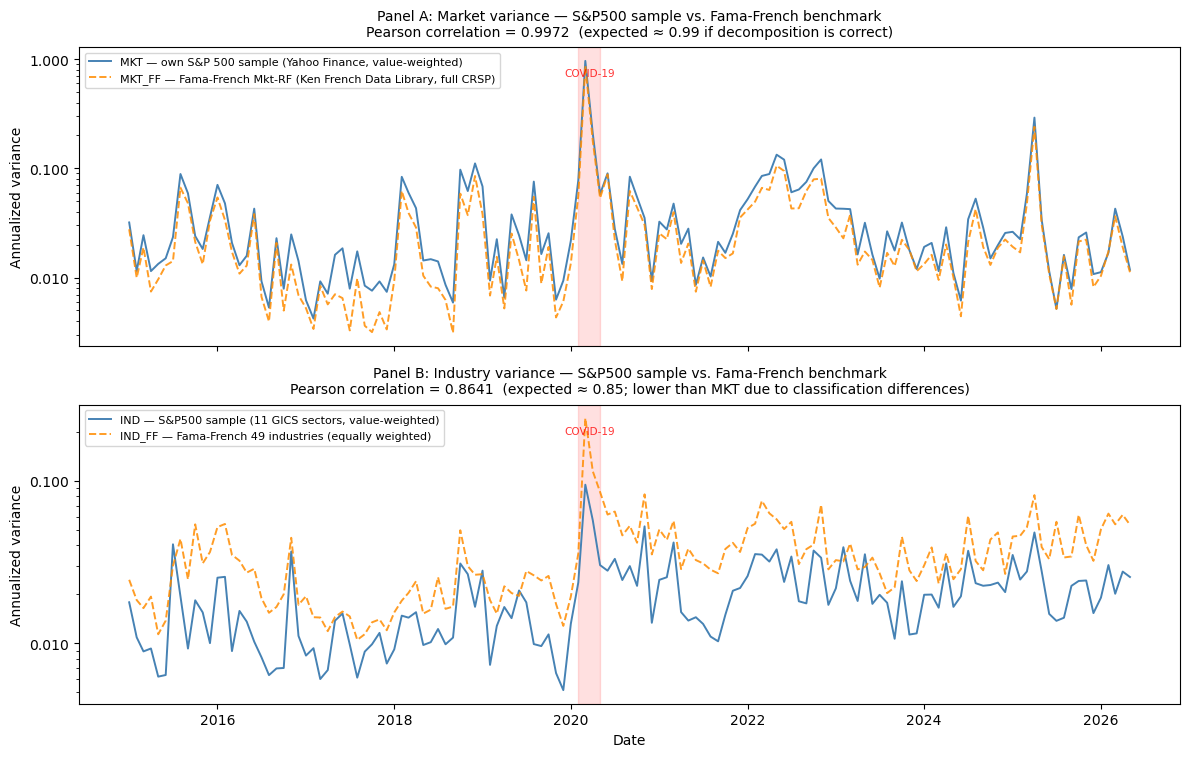

MKT vs MKT_FF correlation: 0.9972  → PASS ✓
IND vs IND_FF correlation: 0.8641  → PASS ✓

Y-axis scale used: log scale
Tip: set USE_LOG_SCALE = False to see the linear version.
     Log scale is recommended for publication — it preserves
     pre/post-COVID variation that linear scale compresses.
MKT vs MKT_FF correlation: 0.9972  → PASS ✓
IND vs IND_FF correlation: 0.8641  → PASS ✓

Y-axis scale used: log scale
Tip: set USE_LOG_SCALE = False to see the linear version.
     Log scale is recommended for publication — it preserves
     pre/post-COVID variation that linear scale compresses.
ERROR: compare dataset not found. Run the FF download cell first.


In [137]:
#Plot of correlations: S&P500 and Fama-French

USE_LOG_SCALE = True   # Set to False for linear scale

if "compare" in dir() and len(compare) > 0:
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    
    #Panel A: Market variance

    axes[0].plot(
        compare.index, compare["MKT"],
        label="MKT — own S&P 500 sample (Yahoo Finance, value-weighted)",
        color="steelblue", linewidth=1.4
    )
    axes[0].plot(
        compare.index, compare["MKT_FF"],
        label="MKT_FF — Fama-French Mkt-RF (Ken French Data Library, full CRSP)",
        color="darkorange", linewidth=1.4,
        linestyle="--", alpha=0.85
    )
    
    mkt_corr = compare["MKT"].corr(compare["MKT_FF"])
    axes[0].set_title(
        f"Panel A: Market variance — S&P500 sample vs. Fama-French benchmark\n"
        f"Pearson correlation = {mkt_corr:.4f}  "
        f"(expected ≈ 0.99 if decomposition is correct)",
        fontsize=10, pad=8
    )
    axes[0].set_ylabel("Annualized variance")
    axes[0].legend(fontsize=8, loc="upper left")
    
    if USE_LOG_SCALE:
        axes[0].set_yscale("log")
        # Fix y-axis tick labels to be readable decimals
        # instead of scientific notation
        from matplotlib.ticker import LogFormatter, LogLocator
        axes[0].yaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f"{x:.3f}" if x >= 0.001 
                             else f"{x:.4f}")
        )
    
    # Panel B: Industry variance-
    axes[1].plot(
        compare.index, compare["IND"],
        label="IND — S&P500 sample (11 GICS sectors, value-weighted)",
        color="steelblue", linewidth=1.4
    )
    axes[1].plot(
        compare.index, compare["IND_FF"],
        label="IND_FF — Fama-French 49 industries (equally weighted)",
        color="darkorange", linewidth=1.4,
        linestyle="--", alpha=0.85
    )
    
    ind_corr = compare["IND"].corr(compare["IND_FF"])
    axes[1].set_title(
        f"Panel B: Industry variance — S&P500 sample vs. Fama-French benchmark\n"
        f"Pearson correlation = {ind_corr:.4f}  "
        f"(expected ≈ 0.85; lower than MKT due to classification differences)",
        fontsize=10, pad=8
    )
    axes[1].set_ylabel("Annualized variance")
    axes[1].set_xlabel("Date")
    axes[1].legend(fontsize=8, loc="upper left")
    
    if USE_LOG_SCALE:
        axes[1].set_yscale("log")
        axes[1].yaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f"{x:.3f}" if x >= 0.001
                             else f"{x:.4f}")
        )
    
    # Shadings

    covid_start = pd.Timestamp("2020-02-01")
    covid_end   = pd.Timestamp("2020-05-01")
    
    for ax in axes:
        ax.axvspan(
            covid_start, covid_end,
            alpha=0.12, color="red", zorder=0
        )

        ax.text(
            pd.Timestamp("2020-03-20"),
            0.93,                          
            "COVID-19",
            transform=ax.get_xaxis_transform(),  
            fontsize=7.5, color="red", alpha=0.8,
            ha="center", va="top"
        )

    #Title

    scale_label = "log scale" if USE_LOG_SCALE else "linear scale"
    fig.suptitle(
        f"Validation: S&P500 volatility decomposition vs. Fama-French benchmarks "
        f"({scale_label})",


        fontsize=11, fontweight="bold",
        y=0.98   
    )
    
    plt.tight_layout(rect=[0, 0, 1, 0.96]) 
    plt.savefig("validation_plot.png", dpi=150, bbox_inches="tight")
    plt.show()

for ax in axes:
    ax.yaxis.set_minor_locator(plt.LogLocator(
        base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10
    ))
    ax.grid(True, which="major", alpha=0.3, linewidth=0.8)
    ax.grid(True, which="minor", alpha=0.1, linewidth=0.4)
    
    #Summary
    print(f"MKT vs MKT_FF correlation: {mkt_corr:.4f}  "
          f"→ {'PASS ✓' if mkt_corr > 0.95 else 'CHECK ✗'}")
    print(f"IND vs IND_FF correlation: {ind_corr:.4f}  "
          f"→ {'PASS ✓' if ind_corr > 0.75 else 'CHECK ✗'}")
    print()
    print(f"Y-axis scale used: {scale_label}")
    print("Tip: set USE_LOG_SCALE = False to see the linear version.")
    print("     Log scale is recommended for publication — it preserves")
    print("     pre/post-COVID variation that linear scale compresses.")

else:
    print("ERROR: compare dataset not found. Run the FF download cell first.")

In [35]:
# Diagnostic check

print("=== FF benchmark series coverage ===")
print(f"ff_compare window : {ff_compare.index.min().date()} "
      f"to {ff_compare.index.max().date()}")
print(f"ff_compare shape  : {ff_compare.shape} "
      f"(months x benchmark series)")
print(f"compare shape     : {compare.shape} "
      f"(common months x your+FF series)")
print(f"Common months     : {len(compare)}")

#Check for NaN
nan_counts = compare.isna().sum()
if nan_counts.sum() == 0:
    print("\nNo missing values in compare dataset. Clean.")
else:
    print(f"\nWarning: missing values detected:")
    print(nan_counts[nan_counts > 0])

print()

# Correlation matrix — the key validation result
print("=== Correlation matrix ===")
print("Expected: MKT vs MKT_FF ~ 0.99, IND vs IND_FF ~ 0.85")
print()
corr_matrix = compare.corr().round(4)
print(corr_matrix)

# Highlighting
mkt_corr = compare["MKT"].corr(compare["MKT_FF"])
ind_corr = compare["IND"].corr(compare["IND_FF"])
print()
print(f"Key validation correlations:")
print(f"  Your MKT vs FF MKT : {mkt_corr:.4f} "
      f"{'PASS' if mkt_corr > 0.95 else 'CHECK'}")
print(f"  Your IND vs FF IND : {ind_corr:.4f} "
      f"{'PASS' if ind_corr > 0.75 else 'CHECK'}")

=== FF benchmark series coverage ===
ff_compare window : 2015-01-01 to 2026-05-01
ff_compare shape  : (137, 2) (months x benchmark series)
compare shape     : (137, 4) (common months x your+FF series)
Common months     : 137

No missing values in compare dataset. Clean.

=== Correlation matrix ===
Expected: MKT vs MKT_FF ~ 0.99, IND vs IND_FF ~ 0.85

           MKT     IND  MKT_FF  IND_FF
MKT     1.0000  0.6980  0.9972  0.8142
IND     0.6980  1.0000  0.6838  0.8641
MKT_FF  0.9972  0.6838  1.0000  0.8186
IND_FF  0.8142  0.8641  0.8186  1.0000

Key validation correlations:
  Your MKT vs FF MKT : 0.9972 PASS
  Your IND vs FF IND : 0.8641 PASS


## 7.2 Diversification (replication)

In [37]:
def diversification_curve_random(rets_window, n_grid=(1, 2, 5, 10, 20, 30, 50, 100, 200, 300),
                                   n_draws=500, seed=42):
    """
    DLR (2007) / CLMX Figure 6 style simulation -- METHOD 1: pure random selection.
    Firms are drawn at random from the entire sample, with no regard to industry membership.

    - benchmark = equally weighted index of the full available universe
    - for each n, draw n_draws random n-stock portfolios, compute annualized std dev of each,
      average across draws, then subtract the benchmark's annualized std dev
    """
    rng = np.random.default_rng(seed)
    cols = rets_window.columns.tolist()

    ew_index_ret = rets_window.mean(axis=1)
    benchmark_std = ew_index_ret.std() * np.sqrt(252)

    results = {}
    for n in n_grid:
        n = min(n, len(cols))
        port_stds = []
        for _ in range(n_draws):
            sample = rng.choice(cols, size=n, replace=False)
            port_ret = rets_window[sample].mean(axis=1)
            port_stds.append(port_ret.std() * np.sqrt(252))
        results[n] = np.mean(port_stds) - benchmark_std

    return pd.Series(results, name="excess_std_dev_random")


def diversification_curve_industry(rets_window, sectors, n_grid=(1, 2, 5, 10, 20, 30, 50, 100, 200, 300),
                                     n_draws=500, seed=42):
    rng = np.random.default_rng(seed)
    cols = rets_window.columns.tolist()
    sec_map = sectors.reindex(cols).dropna()
    industries = sec_map.unique().tolist()
    firms_by_industry = {ind: sec_map[sec_map == ind].index.tolist() for ind in industries}

    ew_index_ret = rets_window.mean(axis=1)
    benchmark_std = ew_index_ret.std() * np.sqrt(252)

    results = {}
    for n in n_grid:
        n = min(n, len(cols))
        port_stds = []
        for _ in range(n_draws):
            n_ind = len(industries)
            base, remainder = divmod(n, n_ind)
            alloc = {ind: base for ind in industries}
            # distribute the remainder to a random subset of industries (without bias)
            extra_inds = rng.choice(industries, size=remainder, replace=False) if remainder > 0 else []
            for ind in extra_inds:
                alloc[ind] += 1

            sample = []
            for ind, k in alloc.items():
                available = firms_by_industry[ind]
                k = min(k, len(available))  
                if k > 0:
                    sample.extend(rng.choice(available, size=k, replace=False))

            port_ret = rets_window[sample].mean(axis=1)
            port_stds.append(port_ret.std() * np.sqrt(252))
        results[n] = np.mean(port_stds) - benchmark_std

    return pd.Series(results, name="excess_std_dev_industry")


# Estimate both methods
n_grid = (1, 2, 5, 10, 20, 30, 50, 100, 200, 300)
clean_rets_div = rets.dropna(how="any")

div_curve_random = diversification_curve_random(clean_rets_div, n_grid=n_grid)
div_curve_industry = diversification_curve_industry(clean_rets_div, sectors, n_grid=n_grid)

div_comparison = pd.DataFrame({
    "Random (DLR Method 1)": div_curve_random,
    "Industry-stratified (DLR Method 2)": div_curve_industry,
})
div_comparison


,Random (DLR Method 1),Industry-stratified (DLR Method 2)
1,0.132940,0.136818
2,0.074846,0.075154
5,0.033765,0.032141
10,0.017448,0.012173
20,0.008538,0.004139
30,0.006180,0.001334
50,0.003533,-0.000586
100,0.001481,-0.002261
200,0.000629,-0.003202
300,0.000307,-0.004784


In [38]:
print(sectors.unique())
print(sectors.value_counts())

['Health Care' 'Information Technology' 'Financials' 'Consumer Staples'
 'Industrials' 'Utilities' 'Materials' 'Real Estate'
 'Consumer Discretionary' 'Energy' 'Communication Services']
GICS Sector
Financials                72
Industrials               70
Information Technology    64
Health Care               56
Consumer Discretionary    44
Consumer Staples          32
Utilities                 29
Real Estate               29
Materials                 24
Energy                    20
Communication Services    20
Name: count, dtype: int64


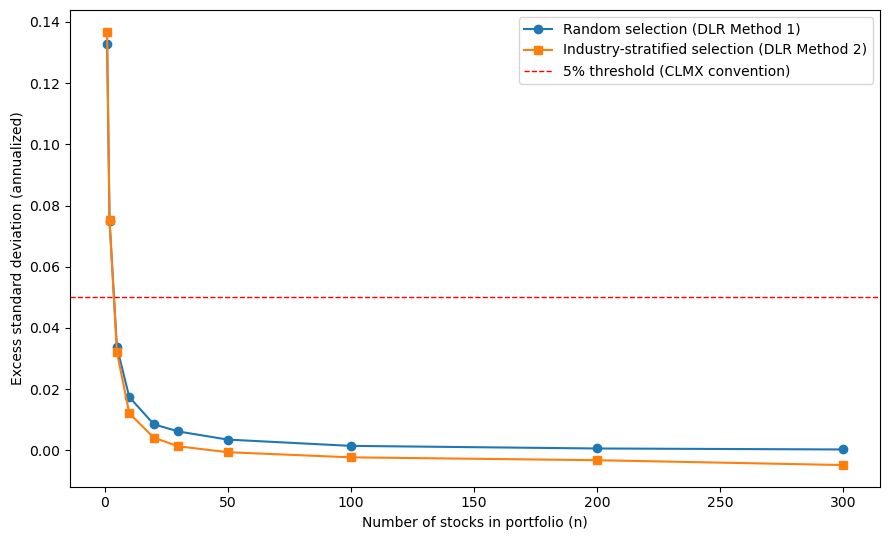

In [39]:
#Diversification plot

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(div_comparison.index, div_comparison["Random (DLR Method 1)"],
        marker="o", label="Random selection (DLR Method 1)")
ax.plot(div_comparison.index, div_comparison["Industry-stratified (DLR Method 2)"],
        marker="s", label="Industry-stratified selection (DLR Method 2)")
ax.axhline(0.05, color="red", linestyle="--", linewidth=1, label="5% threshold (CLMX convention)")
ax.set_xlabel("Number of stocks in portfolio (n)")
ax.set_ylabel("Excess standard deviation (annualized)")
ax.legend()
# Save figure
plt.savefig(
    "Diversification_Random_vs_IndustryStratified.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()

n_needed_random = div_comparison["Random (DLR Method 1)"][div_comparison["Random (DLR Method 1)"] <= 0.05].index.min()
n_needed_industry = div_comparison["Industry-stratified (DLR Method 2)"][div_comparison["Industry-stratified (DLR Method 2)"] <= 0.05].index.min()


## Joint extension - What explains cross-sectional differences in idiosyncratic volatility?

In [41]:
# Firm-level idiosyncratic volatility: time-series variance of eta_jit (eq. 20), averaged

firm_ivol = (eta ** 2).mean() * 252
firm_ivol.name = "IVOL"
firm_ivol.describe()

count    460.000000
mean       0.067303
std        0.047780
min        0.003680
25%        0.035266
50%        0.055127
75%        0.086104
max        0.390851
Name: IVOL, dtype: float64

In [42]:
################# PARA SUSTITUCION / YA ESTAAAAAAAA SUSTITUIDO
CACHE_PATH = "fundamentals_cache.csv"
FUNDAMENTALS_SNAPSHOT_DATE = "2026-07-07"  # record when you pulled this

def pull_fundamentals(ticker):
    """Pull a small set of current fundamentals from yfinance for the cross-sectional regression."""
    try:
        info = yf.Ticker(ticker).info

        market_cap         = info.get("marketCap", np.nan)
        book_per_share     = info.get("bookValue", np.nan)
        shares_outstanding = info.get("sharesOutstanding", np.nan)

        if (book_per_share is not None and shares_outstanding is not None
                and not np.isnan(book_per_share)
                and not np.isnan(shares_outstanding)
                and book_per_share > 0):
            total_book_equity = book_per_share * shares_outstanding
        else:
            total_book_equity = np.nan

        total_debt = info.get("totalDebt", np.nan)

        return {
            "market_cap":   market_cap,
            "total_debt":   total_debt,
            "total_equity": total_book_equity,  # book equity, not market cap
            "roe":          info.get("returnOnEquity", np.nan),
            "beta":         info.get("beta", np.nan),
        }
    except Exception:
        return {"market_cap": np.nan, "total_debt": np.nan, "total_equity": np.nan,
                "roe": np.nan, "beta": np.nan}

if os.path.exists(CACHE_PATH):
    fundamentals = pd.read_csv(CACHE_PATH, index_col=0)
    print(f"Loaded cached fundamentals snapshot from {FUNDAMENTALS_SNAPSHOT_DATE} ({len(fundamentals)} firms).")
else:
    fund_records = {t: pull_fundamentals(t) for t in firm_ivol.index}
    fundamentals = pd.DataFrame(fund_records).T
    fundamentals["leverage"] = fundamentals["total_debt"] / fundamentals["total_equity"]
    fundamentals.to_csv(CACHE_PATH)
    print(f"Pulled and cached fundamentals snapshot ({FUNDAMENTALS_SNAPSHOT_DATE}) for {len(fundamentals)} firms to {CACHE_PATH}")

fundamentals.head()

Loaded cached fundamentals snapshot from 2026-07-07 (459 firms).


,market_cap,total_debt,total_equity,roe,beta,leverage,roe_vol,roe_vol_winsorized
A,3.691103e+10,3.542000e+09,3.691103e+10,0.21331,1.255,0.095960,0.010849,0.010849
AAPL,4.532959e+12,8.471100e+10,4.532959e+12,1.41471,1.097,0.018688,0.071120,0.071120
ABBV,4.612566e+11,7.291200e+10,4.612566e+11,NaN,0.283,0.158073,2.372559,0.190365
ABT,1.661690e+11,3.413600e+10,1.661690e+11,0.12334,0.607,0.205429,0.005986,0.005986
ACGL,3.570762e+10,2.729000e+09,3.570762e+10,0.21306,0.292,0.076426,0.012511,0.012511


In [43]:
# Sanity check 
print("=== Leverage sanity check ===")
print(fundamentals["leverage"].describe())
print()
print("Top 10 highest leverage firms:")
print(fundamentals["leverage"].sort_values(ascending=False).head(10))
print()
print("Firms with negative book equity (leverage will be NaN):")
neg = fundamentals[fundamentals["total_equity"] < 0]
print(f"  {len(neg)} firms")
print()
print("Firms with NaN leverage:")
nan_lev = fundamentals[fundamentals["leverage"].isna()]
print(f"  {len(nan_lev)} firms")
print(nan_lev.index.tolist())

=== Leverage sanity check ===
count    457.000000
mean       0.351248
std        0.475866
min        0.000000
25%        0.092594
50%        0.205396
75%        0.424297
max        4.504130
Name: leverage, dtype: float64

Top 10 highest leverage firms:
CHTR    4.504130
C       3.416313
AES     3.058712
F       2.996328
GS      2.787715
MGM     2.630042
BAC     1.919228
GM      1.879184
WFC     1.793143
NCLH    1.770984
Name: leverage, dtype: float64

Firms with negative book equity (leverage will be NaN):
  0 firms

Firms with NaN leverage:
  2 firms
['FISV', 'STT']


In [44]:
def roe_volatility(ticker):
    """Quarterly ROE volatility, computed from trailing financial statements where available."""
    try:
        tk = yf.Ticker(ticker)
        fin = tk.quarterly_financials
        bs = tk.quarterly_balance_sheet
        if fin.empty or bs.empty or "Net Income" not in fin.index:
            return np.nan
        ni = fin.loc["Net Income"]
        equity_row = "Common Stock Equity" if "Common Stock Equity" in bs.index else "Stockholders Equity"
        if equity_row not in bs.index:
            return np.nan
        eq = bs.loc[equity_row]
        common = ni.index.intersection(eq.index)
        if len(common) < 3:
            return np.nan
        roe_series = ni[common] / eq[common]
        return roe_series.std()
    except Exception:
        return np.nan

# Only compute roe_vol if it isn't already in the cached file
if "roe_vol" not in fundamentals.columns:
    fundamentals["roe_vol"] = [roe_volatility(t) for t in fundamentals.index]
    fundamentals.to_csv(CACHE_PATH)
    print(f"Computed and cached roe_vol for {fundamentals['roe_vol'].notna().sum()} firms")
else:
    print("roe_vol already present in cache, skipping recomputation")

fundamentals[["roe_vol"]].describe()

roe_vol already present in cache, skipping recomputation


,roe_vol
count,458.000000
mean,0.088052
std,0.410517
min,0.000822
25%,0.006317
50%,0.013991
75%,0.033101
max,4.869889


In [45]:
fundamentals["roe_vol"].sort_values(ascending=False).head(10)

MTD     4.869889
CLX     4.216207
STX     4.057946
ABBV    2.372559
CL      1.889017
HAS     1.745840
IT      1.470228
LYV     1.293948
HPQ     1.195192
MAS     1.117075
Name: roe_vol, dtype: float64

In [46]:
# Winsorize roe_vol at the 1st/99th percentile to limit the influence of denominator-driven outliers
lower, upper = fundamentals["roe_vol"].quantile([0.01, 0.99])
fundamentals["roe_vol_winsorized"] = fundamentals["roe_vol"].clip(lower=lower, upper=upper)

print(f"Winsorized roe_vol at [{lower:.4f}, {upper:.4f}]")
fundamentals[["roe_vol", "roe_vol_winsorized"]].describe()

Winsorized roe_vol at [0.0014, 1.8074]


,roe_vol,roe_vol_winsorized
count,458.000000,458.000000
mean,0.088052,0.069783
std,0.410517,0.245365
min,0.000822,0.001358
25%,0.006317,0.006317
50%,0.013991,0.013991
75%,0.033101,0.033101
max,4.869889,1.807406


In [47]:
fundamentals["roe_vol_winsorized"].sort_values(ascending=False).head(10)

MTD     1.807406
ABBV    1.807406
CLX     1.807406
CL      1.807406
STX     1.807406
HAS     1.745840
IT      1.470228
LYV     1.293948
HPQ     1.195192
MAS     1.117075
Name: roe_vol_winsorized, dtype: float64

In [48]:
lower, upper = fundamentals["roe_vol"].quantile([0.05, 0.95])
fundamentals["roe_vol_winsorized"] = fundamentals["roe_vol"].clip(lower=lower, upper=upper)
fundamentals[["roe_vol", "roe_vol_winsorized"]].describe()

,roe_vol,roe_vol_winsorized
count,458.000000,458.000000
mean,0.088052,0.032191
std,0.410517,0.046598
min,0.000822,0.002752
25%,0.006317,0.006317
50%,0.013991,0.013991
75%,0.033101,0.033101
max,4.869889,0.190365


In [49]:
# Only compute roe_vol if it isn't already in the cached file (so reruns are instant)
if "roe_vol" not in fundamentals.columns:
    fundamentals["roe_vol"] = [roe_volatility(t) for t in fundamentals.index]
    fundamentals.to_csv(CACHE_PATH)
    print(f"Computed and cached roe_vol for {fundamentals['roe_vol'].notna().sum()} firms")
else:
    print("roe_vol already present in cache, skipping recomputation")

# Winsorize to address the right-skew from firms with near-zero/negative book equity
lower, upper = fundamentals["roe_vol"].quantile([0.05, 0.95])
fundamentals["roe_vol_winsorized"] = fundamentals["roe_vol"].clip(lower=lower, upper=upper)
fundamentals.to_csv(CACHE_PATH)

fundamentals[["roe_vol", "roe_vol_winsorized"]].describe()

roe_vol already present in cache, skipping recomputation


,roe_vol,roe_vol_winsorized
count,458.000000,458.000000
mean,0.088052,0.032191
std,0.410517,0.046598
min,0.000822,0.002752
25%,0.006317,0.006317
50%,0.013991,0.013991
75%,0.033101,0.033101
max,4.869889,0.190365


In [50]:
reg_df = pd.DataFrame({"IVOL": firm_ivol}).join(fundamentals).join(sector_map.rename("sector"))
reg_df["log_mcap"] = np.log(reg_df["market_cap"].clip(lower=1))
reg_df["log_IVOL"] = np.log(reg_df["IVOL"].clip(lower=1e-8))

reg_df = reg_df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["log_IVOL", "log_mcap", "leverage", "roe_vol_winsorized", "sector"]
)
print(f"Regression sample: {len(reg_df)} firms")
reg_df.head()

Regression sample: 456 firms


,IVOL,market_cap,total_debt,total_equity,roe,beta,leverage,roe_vol,roe_vol_winsorized,sector,log_mcap,log_IVOL
Ticker,,,,,,,,,,,,
A,0.044815,3.691103e+10,3.542000e+09,3.691103e+10,0.21331,1.255,0.095960,0.010849,0.010849,Health Care,24.331776,-3.105207
AAPL,0.039379,4.532959e+12,8.471100e+10,4.532959e+12,1.41471,1.097,0.018688,0.071120,0.071120,Information Technology,29.142396,-3.234514
ABBV,0.040247,4.612566e+11,7.291200e+10,4.612566e+11,NaN,0.283,0.158073,2.372559,0.190365,Health Care,26.857220,-3.212727
ABT,0.029140,1.661690e+11,3.413600e+10,1.661690e+11,0.12334,0.607,0.205429,0.005986,0.005986,Health Care,25.836271,-3.535634
ACGL,0.041063,3.570762e+10,2.729000e+09,3.570762e+10,0.21306,0.292,0.076426,0.012511,0.012511,Financials,24.298630,-3.192647


In [51]:
X = pd.get_dummies(
    reg_df[["log_mcap", "leverage", "roe_vol_winsorized", "sector"]],
    columns=["sector"], drop_first=True
)
X = X.astype(float)
X = sm.add_constant(X)
y = reg_df["log_IVOL"].astype(float)

model = sm.OLS(y, X, missing="drop").fit(cov_type="HC1")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               log_IVOL   R-squared:                       0.556
Model:                            OLS   Adj. R-squared:                  0.542
Method:                 Least Squares   F-statistic:                     56.81
Date:                Fri, 10 Jul 2026   Prob (F-statistic):           1.17e-85
Time:                        10:54:04   Log-Likelihood:                -299.20
No. Observations:                 456   AIC:                             626.4
Df Residuals:                     442   BIC:                             684.1
Df Model:                          13                                         
Covariance Type:                  HC1                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [52]:
fundamentals["leverage"].describe()

count    457.000000
mean       0.351248
std        0.475866
min        0.000000
25%        0.092594
50%        0.205396
75%        0.424297
max        4.504130
Name: leverage, dtype: float64

In [53]:
lower_lev, upper_lev = fundamentals["leverage"].quantile([0.01, 0.99])
fundamentals["leverage_winsorized"] = fundamentals["leverage"].clip(lower=lower_lev, upper=upper_lev)
fundamentals["leverage_winsorized"].describe()

count    457.000000
mean       0.344107
std        0.428943
min        0.000777
25%        0.092594
50%        0.205396
75%        0.424297
max        2.699418
Name: leverage_winsorized, dtype: float64

In [54]:
print([c for c in X.columns if "sector" not in c.lower()])

all_sectors = set(reg_df["sector"].unique())
dummy_sectors = set(c.replace("sector_", "") for c in X.columns if c.startswith("sector_"))
print("Baseline (omitted) sector:", all_sectors - dummy_sectors)

['const', 'log_mcap', 'leverage', 'roe_vol_winsorized']
Baseline (omitted) sector: {'Communication Services'}


In [55]:
pd.set_option("display.max_rows", None)
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               log_IVOL   R-squared:                       0.556
Model:                            OLS   Adj. R-squared:                  0.542
Method:                 Least Squares   F-statistic:                     56.81
Date:                Fri, 10 Jul 2026   Prob (F-statistic):           1.17e-85
Time:                        10:54:04   Log-Likelihood:                -299.20
No. Observations:                 456   AIC:                             626.4
Df Residuals:                     442   BIC:                             684.1
Df Model:                          13                                         
Covariance Type:                  HC1                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

## Valencia's extension: Economic regimes (sub-period) evaluation of idiosyncratic volatility (pre-covid / covid / post-covid) 

In [57]:
#Memory check
print("=== Memory check ===")
base_required = {
    "close_prices": "Adjusted closing prices (Step 2)",
    "sector_map":   "GICS sector mapping (Step 1)",
    "w_vw":         "Value weights (Step 3)",
    "rf_daily":     "Daily risk-free rate (Step 3)",
}
missing_base = []
for obj, desc in base_required.items():
    exists = obj in dir()
    print(f"  {obj:<15} {'OK' if exists else 'MISSING'}  {desc}")
    if not exists:
        missing_base.append(obj)

if missing_base:
    raise NameError(
        f"\nMISSING base objects: {missing_base}\n"
        f"These come from early pipeline steps.\n"
        f"Rerun cells: data download, weight computation."
    )
print()

# Rebuildt

if "excess_rets" not in dir():
    print("Rebuilding excess_rets from close_prices and rf_daily...")
    rets        = close_prices.pct_change().dropna(how="all")
    excess_rets = rets.sub(rf_daily, axis=0).dropna(how="all")
    print(f"excess_rets rebuilt: {excess_rets.shape}\n")
else:
    excess_rets = excess_rets
    print(f"excess_rets found in memory: {excess_rets.shape}\n")

# Rebuild sectors 

if "sectors" not in dir():
    print("Rebuilding sectors...")
    sectors = sector_map.reindex(excess_rets.columns)
    print(f"sectors rebuilt: {sectors.nunique()} unique sectors\n")
else:
    sectors = sectors.reindex(excess_rets.columns)
    print(f"sectors found: {sectors.nunique()} unique sectors\n")

#Rebuild mkt_ret, ind_ret, eps, eta if not in memory
def rebuild_return_components(excess_rets, sectors, w_vw):
    """
    Recomputes market return, industry returns, and residuals
    from scratch. Mirrors Steps 5a of the main pipeline.
    """
    mkt_ret = (excess_rets * w_vw).sum(axis=1)

    ind_ret = pd.DataFrame(index=excess_rets.index)
    for sec in sectors.dropna().unique():
        members  = sectors[sectors == sec].index.intersection(
                       excess_rets.columns)
        w_sec    = w_vw[members] / w_vw[members].sum()
        ind_ret[sec] = (excess_rets[members] * w_sec).sum(axis=1)

    eps = ind_ret.sub(mkt_ret, axis=0)

    firm_industry_ret = pd.DataFrame(
        {t: ind_ret[sectors[t]] for t in excess_rets.columns
         if sectors[t] in ind_ret.columns}
    )
    eta = excess_rets[firm_industry_ret.columns] - firm_industry_ret

    return mkt_ret, ind_ret, eps, eta

needs_rebuild = any(obj not in dir() for obj in ["mkt_ret","eps","eta"])

if needs_rebuild:
    print("Rebuilding mkt_ret, eps, eta...")
    mkt_ret, ind_ret, eps, eta = rebuild_return_components(
        excess_rets, sectors, w_vw
    )
    print(f"mkt_ret shape : {mkt_ret.shape}")
    print(f"eps shape     : {eps.shape}  (days x sectors)")
    print(f"eta shape     : {eta.shape}  (days x firms)\n")
else:
    print("mkt_ret, eps, eta found in memory.\n")

# Define monthly_volatility_components if not in memory

def monthly_volatility_components(mkt_ret, eps, eta, w_vw, sectors):
    """
    Build monthly MKT, IND, FIRM series following CLMX eq (17)-(22).

    MKT_t  = sum over days s in month t of (R_ms - mean(R_m))^2 * 12
    IND_t  = value-weighted average across sectors of
             sum_s eps_is^2 within month t, annualized
    FIRM_t = value-weighted average across firms of
             sum_s eta_js^2 within month t, annualized
    """
    months = mkt_ret.index.to_period("M")
    mu_m   = mkt_ret.mean()

    mkt_monthly = ((mkt_ret - mu_m) ** 2).groupby(months).sum() * 12

    sector_weight  = w_vw.groupby(
        sectors.reindex(w_vw.index)
    ).sum()
    eps_sq_monthly = (eps ** 2).groupby(months).sum()
    
    common_sectors = eps_sq_monthly.columns.intersection(
        sector_weight.index
    )
    ind_monthly = (
        eps_sq_monthly[common_sectors] * sector_weight[common_sectors]
    ).sum(axis=1) * 12

    eta_sq_monthly = (eta ** 2).groupby(months).sum()
    common_firms   = eta_sq_monthly.columns.intersection(w_vw.index)
    firm_monthly   = (
        eta_sq_monthly[common_firms] * w_vw[common_firms]
    ).sum(axis=1) * 12

    out = pd.DataFrame({
        "MKT":  mkt_monthly,
        "IND":  ind_monthly,
        "FIRM": firm_monthly,
    })
    out.index = out.index.to_timestamp()
    return out

print("monthly_volatility_components function defined.\n")

#Compute volatility components by subperiod

period_ranges = {
    "pre_covid_2015_2019": ("2015-01-01", "2019-12-31"),
    "covid_2020":          ("2020-01-01", "2020-12-31"),
    "post_covid_2021_on":  ("2021-01-01", None),
}

period_vol_components = {}

print("Computing MKT/IND/FIRM by subperiod...")
for name, (start, end) in period_ranges.items():
    mkt_sub = mkt_ret.loc[start:end] if end else mkt_ret.loc[start:]
    eps_sub = eps.loc[start:end]     if end else eps.loc[start:]
    eta_sub = eta.loc[start:end]     if end else eta.loc[start:]

    if len(mkt_sub) < 50:
        print(f"  {name}: only {len(mkt_sub)} days — SKIPPED")
        continue

    print(f"  {name}: {len(mkt_sub)} days...", end=" ")
    period_vol_components[name] = monthly_volatility_components(
        mkt_sub, eps_sub, eta_sub, w_vw, sectors
    )
    print("done.")

print()

# Summary table

summary_table = pd.DataFrame({
    name: comp.mean()
    for name, comp in period_vol_components.items()
}).T

total_var = summary_table.sum(axis=1)

summary_table["MKT_share_%"] = (
    summary_table["MKT"] / total_var * 100
).round(1)

summary_table["IND_share_%"] = (
    summary_table["IND"] / total_var * 100
).round(1)

summary_table["FIRM_share_%"] = (
    summary_table["FIRM"] / total_var * 100
).round(1)

summary_table = summary_table[[
    "MKT",  "MKT_share_%",
    "IND",  "IND_share_%",
    "FIRM", "FIRM_share_%"
]].round(4)

print("Average annualized MKT / IND / FIRM volatility by sub-period:")
print()
print(summary_table.to_string())
print()

# Sanity check: shares should sum to 100
share_cols = ["MKT_share_%", "IND_share_%", "FIRM_share_%"]
print("Share totals (should be 100%):")
print(summary_table[share_cols].sum(axis=1).round(1).to_string())

# Rebuild vol_components (full sample) if missing
if "vol_components" not in dir():
    print("Rebuilding full-sample vol_components...")
    vol_components = monthly_volatility_components(
        mkt_ret, eps, eta, w_vw, sectors
    )
    print(f"vol_components rebuilt: {vol_components.shape}")
    print(vol_components.describe().round(4))
else:
    print("vol_components already in memory.")

=== Memory check ===
  close_prices    OK  Adjusted closing prices (Step 2)
  sector_map      OK  GICS sector mapping (Step 1)
  w_vw            OK  Value weights (Step 3)
  rf_daily        OK  Daily risk-free rate (Step 3)

excess_rets found in memory: (2880, 460)

sectors found: 11 unique sectors

Rebuilding mkt_ret, eps, eta...
mkt_ret shape : (2880,)
eps shape     : (2880, 11)  (days x sectors)
eta shape     : (2880, 460)  (days x firms)

monthly_volatility_components function defined.

Computing MKT/IND/FIRM by subperiod...
  pre_covid_2015_2019: 1257 days... done.
  covid_2020: 253 days... done.
  post_covid_2021_on: 1370 days... done.

Average annualized MKT / IND / FIRM volatility by sub-period:

                        MKT  MKT_share_%     IND  IND_share_%    FIRM  FIRM_share_%
pre_covid_2015_2019  0.0269         32.9  0.0134         16.4  0.0415          50.7
covid_2020           0.1366         54.1  0.0352         13.9  0.0807          32.0
post_covid_2021_on   0.0387       

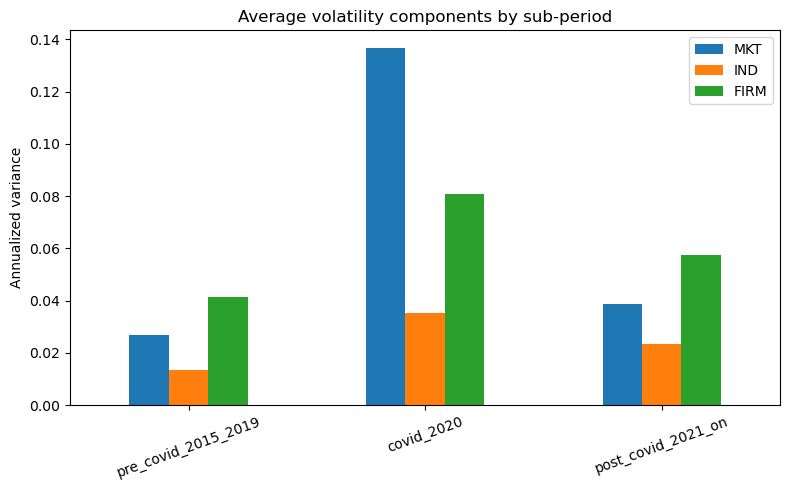

In [58]:
#Plot of volatility components

fig, ax = plt.subplots(figsize=(8, 5))
summary_table[["MKT", "IND", "FIRM"]].plot(kind="bar", ax=ax)
ax.set_title("Average volatility components by sub-period")
ax.set_ylabel("Annualized variance")
ax.set_xticklabels(summary_table.index, rotation=20)
plt.tight_layout()
plt.show()

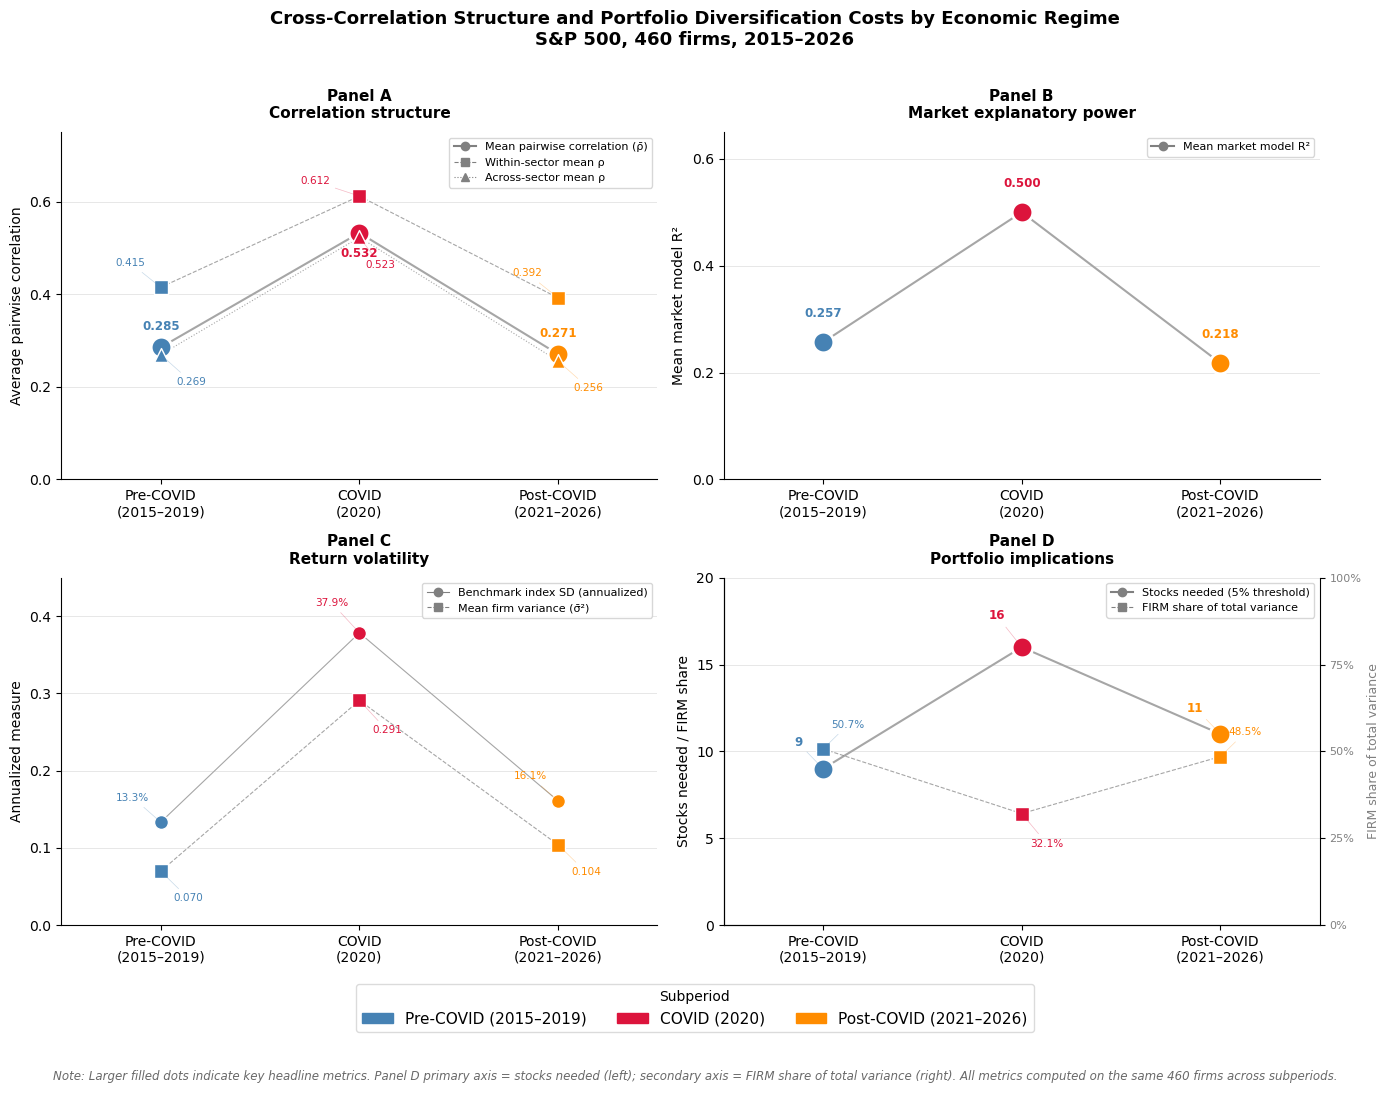

Saved: connected_dot_plot.png


In [59]:
#Cross-correlation and diversification among periods - Summary chart

periods = ["Pre-COVID\n(2015–2019)", "COVID\n(2020)", "Post-COVID\n(2021–2026)"]
x_pos   = [0, 1, 2]

metrics = {
    "Mean pairwise\ncorrelation (ρ̄)": {
        "values":    [0.2852, 0.5324, 0.2707],
        "panel":     "A",
        "format":    ".3f",
        "highlight": True,
    },
    "Within-sector\nmean ρ": {
        "values":    [0.4149, 0.6118, 0.3921],
        "panel":     "A",
        "format":    ".3f",
        "highlight": False,
    },
    "Across-sector\nmean ρ": {
        "values":    [0.2694, 0.5228, 0.2560],
        "panel":     "A",
        "format":    ".3f",
        "highlight": False,
    },
    "Mean market\nmodel R²": {
        "values":    [0.2568, 0.5001, 0.2178],
        "panel":     "B",
        "format":    ".3f",
        "highlight": True,
    },
    "Benchmark index\nSD (annualized)": {
        "values":    [0.1333, 0.3786, 0.1609],
        "panel":     "C",
        "format":    ".1%",
        "highlight": False,
    },
    "Mean firm\nvariance (σ̄²)": {
        "values":    [0.0698, 0.2910, 0.1041],
        "panel":     "C",
        "format":    ".3f",
        "highlight": False,
    },
    "Stocks needed\n(5% threshold)": {
        "values":    [9, 16, 11],
        "panel":     "D",
        "format":    ".0f",
        "highlight": True,
    },
    "FIRM share of\ntotal variance": {
        "values":    [0.507, 0.321, 0.485],
        "panel":     "D",
        "format":    ".1%",
        "highlight": False,
    },
}

panel_config = {
    "A": {
        "title":  "Panel A\nCorrelation structure",
        "ylabel": "Average pairwise correlation",
        "ylim":   (0.0, 0.75),
        "yticks": [0.0, 0.2, 0.4, 0.6],
    },
    "B": {
        "title":  "Panel B\nMarket explanatory power",
        "ylabel": "Mean market model R²",
        "ylim":   (0.0, 0.65),
        "yticks": [0.0, 0.2, 0.4, 0.6],
    },
    "C": {
        "title":  "Panel C\nReturn volatility",
        "ylabel": "Annualized measure",
        "ylim":   (0.0, 0.45),
        "yticks": [0.0, 0.1, 0.2, 0.3, 0.4],
    },
    "D": {
        "title":  "Panel D\nPortfolio implications",
        "ylabel": "Stocks needed / FIRM share",
        "ylim":   (0.0, 20),
        "yticks": [0, 5, 10, 15, 20],
    },
}

period_colors = {
    "Pre-COVID\n(2015–2019)":  "steelblue",
    "COVID\n(2020)":           "crimson",
    "Post-COVID\n(2021–2026)": "darkorange",
}

line_styles   = ["-", "--", ":"]
marker_styles = ["o", "s", "^"]


# Format

manual_offsets = {
    # Panel A — mean correlation (centered above)
    ("Mean pairwise",  0): (0,    10),
    ("Mean pairwise",  1): (0,    -10),
    ("Mean pairwise",  2): (0,    10),
    # Panel A — within-sector (left side)
    ("Within-sector",  0): (-22,  14),
    ("Within-sector",  1): (-32,  7),
    ("Within-sector",  2): (-22,  14),
    # Panel A — across-sector (right side, below)
    ("Across-sector",  0): (22,  -16),
    ("Across-sector",  1): (15,  -16),
    ("Across-sector",  2): (22,  -16),
    # Panel B — market model R² (centered above)
    ("Mean market",    0): (0,    16),
    ("Mean market",    1): (0,    16),
    ("Mean market",    2): (0,    16),
    # Panel C — benchmark SD (left side, above)
    ("Benchmark",      0): (-20,  14),
    ("Benchmark",      1): (-20,  18),
    ("Benchmark",      2): (-20,  14),
    # Panel C — firm variance (right side, below)
    ("Mean firm",      0): (20,  -16),
    ("Mean firm",      1): (20,  -18),
    ("Mean firm",      2): (20,  -16),
    # Panel D — stocks needed (left side, above)
    ("Stocks needed",  0): (-18,  14),
    ("Stocks needed",  1): (-18,  18),
    ("Stocks needed",  2): (-18,  14),
    # Panel D — FIRM share (right side, above)
    ("FIRM share",     0): (18,   14),
    ("FIRM share",     1): (18,  -18),
    ("FIRM share",     2): (18,   14),
}

def get_offset(metric_name, xi):
    """
    Look up the manual offset for a given metric and period.
    Tries each keyword in manual_offsets against the metric name.
    Falls back to (0, 16) if no match found.
    """
    clean = metric_name.replace("\n", " ")
    for (keyword, period_xi), (ox, oy) in manual_offsets.items():
        if keyword.lower() in clean.lower() and period_xi == xi:
            return ox, oy
    # Default: above the dot, centered
    return 0, 16

plt.close("all")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes_flat  = [axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]]
panel_axes = {
    "A": axes_flat[0],
    "B": axes_flat[1],
    "C": axes_flat[2],
    "D": axes_flat[3],
}

for panel_id, ax in panel_axes.items():
    cfg = panel_config[panel_id]

    panel_metrics = {
        k: v for k, v in metrics.items()
        if v["panel"] == panel_id
    }

    for m_idx, (metric_name, mdata) in enumerate(
        panel_metrics.items()
    ):
        values    = mdata["values"]
        highlight = mdata["highlight"]   # defined here — no NameError
        fmt       = mdata["format"]
        ls        = line_styles[m_idx % len(line_styles)]
        mk        = marker_styles[m_idx % len(marker_styles)]

        # Scale values for plotting
        plot_values = list(values)
        if panel_id == "D" and "FIRM" in metric_name:
            # Scale FIRM share (0–1) onto the stocks axis (0–20)
            plot_values = [v * 20 for v in values]

 
        ax.plot(
            x_pos, plot_values,
            color="gray",
            linewidth=1.5 if highlight else 0.8,
            linestyle=ls,
            zorder=1,
            alpha=0.7
        )

        for xi, (val, plot_val) in enumerate(
            zip(values, plot_values)
        ):
            col        = list(period_colors.values())[xi]
            dot_size   = 220 if highlight else 100
            edge_width = 2.0 if highlight else 1.0

            # Dot
            ax.scatter(
                xi, plot_val,
                s=dot_size,
                color=col,
                marker=mk,
                zorder=3,
                edgecolors="white",
                linewidths=edge_width
            )

            # Format label text
            if panel_id == "D" and "FIRM" in metric_name:
                label_text = f"{val:.1%}"
            elif fmt == ".1%":
                label_text = f"{val:.1%}"
            elif fmt == ".3f":
                label_text = f"{val:.3f}"
            elif fmt == ".0f":
                label_text = f"{int(val)}"
            else:
                label_text = str(val)

            # Get offset from manual table
            offset_x, offset_y = get_offset(metric_name, xi)

            # Draw label
            ax.annotate(
                label_text,
                xy=(xi, plot_val),
                xytext=(offset_x, offset_y),
                textcoords="offset points",
                ha="center",
                va="bottom" if offset_y >= 0 else "top",
                fontsize=8.5 if highlight else 7.5,
                fontweight="bold" if highlight else "normal",
                color=col,
                arrowprops=dict(
                    arrowstyle="-",
                    color=col,
                    lw=0.5,
                    alpha=0.3
                ) if abs(offset_x) > 12 else None,
            )

#Legend
        ax.plot(
            [], [],
            color="gray",
            linestyle=ls,
            marker=mk,
            markersize=6,
            label=metric_name.replace("\n", " "),
            linewidth=1.5 if highlight else 0.8
        )


    # Axis formatting
    ax.set_title(
        cfg["title"], fontsize=11, fontweight="bold", pad=10
    )
    ax.set_ylabel(cfg["ylabel"], fontsize=10)
    ax.set_xlim(-0.5, 2.5)
    ax.set_ylim(cfg["ylim"])
    ax.set_xticks(x_pos)
    ax.set_xticklabels(
        ["Pre-COVID\n(2015–2019)",
         "COVID\n(2020)",
         "Post-COVID\n(2021–2026)"],
        fontsize=10
    )
    ax.set_yticks(cfg["yticks"])
    ax.grid(True, axis="y", alpha=0.3, linewidth=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        fontsize=8,
        loc="upper right",
        framealpha=0.9,
        edgecolor="lightgray"
    )

    # Secondary axis for Panel D (FIRM share scale)
    if panel_id == "D":
        ax2 = ax.twinx()
        ax2.set_ylim(0, 1.0)
        ax2.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
        ax2.set_yticklabels(
            ["0%", "25%", "50%", "75%", "100%"],
            fontsize=8, color="gray"
        )
        ax2.set_ylabel(
            "FIRM share of total variance",
            fontsize=9, color="gray"
        )
        ax2.spines["top"].set_visible(False)


#Global period-color legend at the bottom

legend_patches = [
    mpatches.Patch(color=c, label=p.replace("\n", " "))
    for p, c in period_colors.items()
]
fig.legend(
    handles=legend_patches,
    loc="lower center",
    ncol=3,
    fontsize=11,
    frameon=True,
    edgecolor="lightgray",
    bbox_to_anchor=(0.5, -0.02),
    title="Subperiod",
    title_fontsize=10
)

# Figure title and note

fig.suptitle(
    "Cross-Correlation Structure and Portfolio Diversification "
    "Costs by Economic Regime\n"
    "S&P 500, 460 firms, 2015–2026",
    fontsize=13,
    fontweight="bold",
    y=1.01
)

fig.text(
    0.5, -0.06,
    "Note: Larger filled dots indicate key headline metrics. "
    "Panel D primary axis = stocks needed (left); "
    "secondary axis = FIRM share of total variance (right). "
    "All metrics computed on the same 460 firms across subperiods.",
    ha="center",
    fontsize=8.5,
    color="dimgray",
    style="italic"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("connected_dot_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: connected_dot_plot.png")

## Matheus' Extension: IVOL groups

Original returns: (2880, 460)
Clean returns: (2880, 460)
High-IVOL group: 228 firms
Low-IVOL group:  228 firms


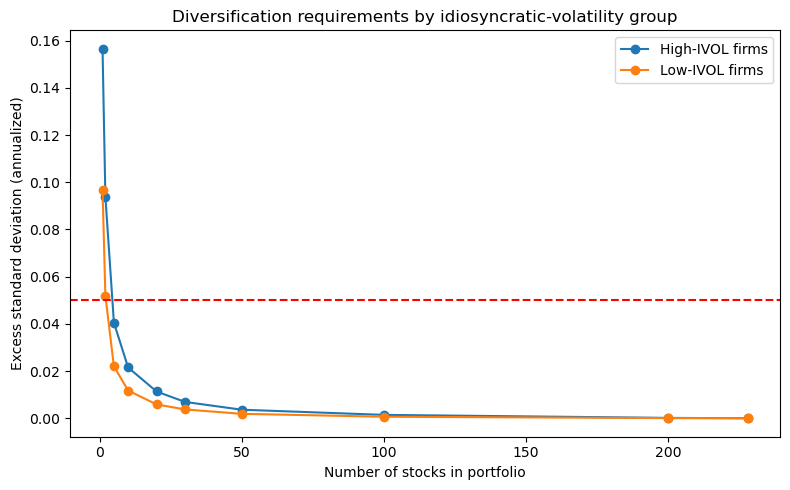

Stocks needed for <5% excess std dev, HIGH-IVOL group: 5
Stocks needed for <5% excess std dev, LOW-IVOL group:  5

A portfolio drawn only from high-IVOL firms should require visibly more names to reach the
same 5% diversification threshold than a portfolio drawn from low-IVOL firms.


In [61]:
# Remove firms with missing daily returns
clean_rets = rets.dropna(how="any")

print("Original returns:", rets.shape)
print("Clean returns:", clean_rets.shape)

# Classify firms in IVOL groups
median_ivol = reg_df["IVOL"].median()
high_ivol_firms = reg_df[reg_df["IVOL"] >= median_ivol].index.tolist()
low_ivol_firms  = reg_df[reg_df["IVOL"] <  median_ivol].index.tolist()

high_ivol_firms = [t for t in high_ivol_firms if t in clean_rets.columns]
low_ivol_firms  = [t for t in low_ivol_firms  if t in clean_rets.columns]

print(f"High-IVOL group: {len(high_ivol_firms)} firms")
print(f"Low-IVOL group:  {len(low_ivol_firms)} firms")

div_high = diversification_curve_random(clean_rets[high_ivol_firms])
div_low  = diversification_curve_random(clean_rets[low_ivol_firms])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(div_high.index, div_high.values, marker="o", label="High-IVOL firms")
ax.plot(div_low.index,  div_low.values,  marker="o", label="Low-IVOL firms")
ax.axhline(0.05, color="red", linestyle="--")
ax.set_xlabel("Number of stocks in portfolio")
ax.set_ylabel("Excess standard deviation (annualized)")
ax.set_title("Diversification requirements by idiosyncratic-volatility group")
ax.legend()
plt.tight_layout()
plt.show()

n_needed_high = div_high[div_high <= 0.05].index.min()
n_needed_low  = div_low[div_low <= 0.05].index.min()
print(f"Stocks needed for <5% excess std dev, HIGH-IVOL group: {n_needed_high}")
print(f"Stocks needed for <5% excess std dev, LOW-IVOL group:  {n_needed_low}")
print()
print("A portfolio drawn only from high-IVOL firms should require visibly more names to reach the")
print("same 5% diversification threshold than a portfolio drawn from low-IVOL firms.")

In [62]:
# Create IVOL group
reg_df["IVOL_group"] = np.where(
    reg_df["IVOL"] >= median_ivol,
    "High IVOL",
    "Low IVOL"
)

# Count firms by sector and IVOL group
sector_counts = (
    reg_df
    .groupby(["sector", "IVOL_group"])
    .size()
    .unstack(fill_value=0)
)

# Add totals
sector_counts["Total"] = sector_counts.sum(axis=1)

print(sector_counts.sort_values("Total", ascending=False))

# PERCENTAGE
sector_percent = sector_counts.copy()

sector_percent["% High IVOL"] = (
    100 * sector_percent["High IVOL"] / sector_percent["Total"]
)

sector_percent["% Low IVOL"] = (
    100 * sector_percent["Low IVOL"] / sector_percent["Total"]
)

print(
    sector_percent[["High IVOL", "Low IVOL", "% High IVOL", "% Low IVOL"]]
    .sort_values("% High IVOL", ascending=False)
)

IVOL_group              High IVOL  Low IVOL  Total
sector                                            
Financials                     15        55     70
Industrials                    22        48     70
Information Technology         57         7     64
Health Care                    31        24     55
Consumer Discretionary         43         1     44
Consumer Staples               11        21     32
Real Estate                     4        25     29
Utilities                       2        26     28
Materials                      12        12     24
Communication Services         18         2     20
Energy                         13         7     20
IVOL_group              High IVOL  Low IVOL  % High IVOL  % Low IVOL
sector                                                              
Consumer Discretionary         43         1    97.727273    2.272727
Communication Services         18         2    90.000000   10.000000
Information Technology         57         7    89.062500   10

In [63]:
# PANEL A: Correlations matrices

# calculate correlations matrices
corr_high = clean_rets[high_ivol_firms].corr()
corr_low  = clean_rets[low_ivol_firms].corr()

# restirict to sectors
sector_high = sectors.loc[high_ivol_firms]
sector_low  = sectors.loc[low_ivol_firms]

# Calculate within and across-sector correlation
def mean_sector_correlations(corr_matrix, sector_labels):

    within = []
    across = []

    firms = corr_matrix.columns

    for i in range(len(firms)):
        for j in range(i+1, len(firms)):

            f1 = firms[i]
            f2 = firms[j]

            rho = corr_matrix.loc[f1, f2]

            if sector_labels[f1] == sector_labels[f2]:
                within.append(rho)
            else:
                across.append(rho)

    return np.mean(within), np.mean(across)

# Apply to High and Low IVOL
within_high, across_high = mean_sector_correlations(
    corr_high,
    sector_high
)

within_low, across_low = mean_sector_correlations(
    corr_low,
    sector_low
)
# Results
print("Low IVOL")
print("Within:", within_low)
print("Across:", across_low)

print()

print("High IVOL")
print("Within:", within_high)
print("Across:", across_high)

# PANEL B: VOLATILITY DECOMPOSITION SHARE
# Calculate volatility share by group
def volatility_share_by_group(firms, mkt_ret, eps, eta, w_vw, sectors):

    months = mkt_ret.index.to_period("M")

    # -------------------
    # MARKET COMPONENT
    # -------------------
    mu_m = mkt_ret.mean()

    mkt_monthly = (
        ((mkt_ret - mu_m)**2)
        .groupby(months)
        .sum()
        * 12
    )


    # -------------------
    # FIRM COMPONENT
    # -------------------
    eta_group = eta[firms]

    w_group = w_vw[firms]

    # normalize weights inside group
    w_group = w_group / w_group.sum()

    eta_sq_monthly = (
        (eta_group**2)
        .groupby(months)
        .sum()
    )

    firm_monthly = (
        eta_sq_monthly
        * w_group
    ).sum(axis=1) * 12


    # -------------------
    # INDUSTRY COMPONENT
    # -------------------
    # identify sectors represented by these firms

    group_sectors = sectors.loc[firms]

    sector_weights = (
        w_group
        .groupby(group_sectors)
        .sum()
    )


    eps_sq_monthly = (
        (eps**2)
        .groupby(months)
        .sum()
    )

    # keep only sectors in the group
    eps_sq_monthly = eps_sq_monthly[sector_weights.index]

    ind_monthly = (
        eps_sq_monthly
        * sector_weights
    ).sum(axis=1) * 12


    # -------------------
    # Combine
    # -------------------

    components = pd.DataFrame({
        "MKT": mkt_monthly,
        "IND": ind_monthly,
        "FIRM": firm_monthly
    })


    avg_components = components.mean()

    shares = avg_components / avg_components.sum()

    return shares, avg_components

# Run 
shares_high, values_high = volatility_share_by_group(
    high_ivol_firms,
    mkt_ret,
    eps,
    eta,
    w_vw,
    sectors
)


shares_low, values_low = volatility_share_by_group(
    low_ivol_firms,
    mkt_ret,
    eps,
    eta,
    w_vw,
    sectors
)

# Results
print()
print("Low IVOL")
print(shares_low)

print()

print("High IVOL")
print(shares_high)

# PANEL C: Mean Variation (Volatility)

annualized_var = clean_rets.var() * 252

# Split into groups
low_var = annualized_var[low_ivol_firms]

high_var = annualized_var[high_ivol_firms]

# Avg withing group 
mean_var_low = low_var.mean()

mean_var_high = high_var.mean()

# Results
print()
print("Low IVOL mean variance:", mean_var_low)
print("High IVOL mean variance:", mean_var_high)

# PANEL D: Diversification Treshhold

div_high = diversification_curve_random(
    clean_rets[high_ivol_firms]
)


div_low = diversification_curve_random(
    clean_rets[low_ivol_firms]
)

# Find 5% treshold
div_high[div_high <= 0.05].index.min()

n_needed_high = div_high[
    div_high <= 0.05
].index.min()


n_needed_low = div_low[
    div_low <= 0.05
].index.min()

# Results
print(
    "Stocks needed for <5% excess volatility"
)

print(
    "Low IVOL:",
    n_needed_low
)

print(
    "High IVOL:",
    n_needed_high
)

Low IVOL
Within: 0.5421281257357056
Across: 0.36994210447260906

High IVOL
Within: 0.38586166667868393
Across: 0.2955817937008557

Low IVOL
MKT     0.469749
IND     0.237641
FIRM    0.292609
dtype: float64

High IVOL
MKT     0.273349
IND     0.118404
FIRM    0.608248
dtype: float64

Low IVOL mean variance: 0.07153051040495381
High IVOL mean variance: 0.13876523652667744
Stocks needed for <5% excess volatility
Low IVOL: 5
High IVOL: 5


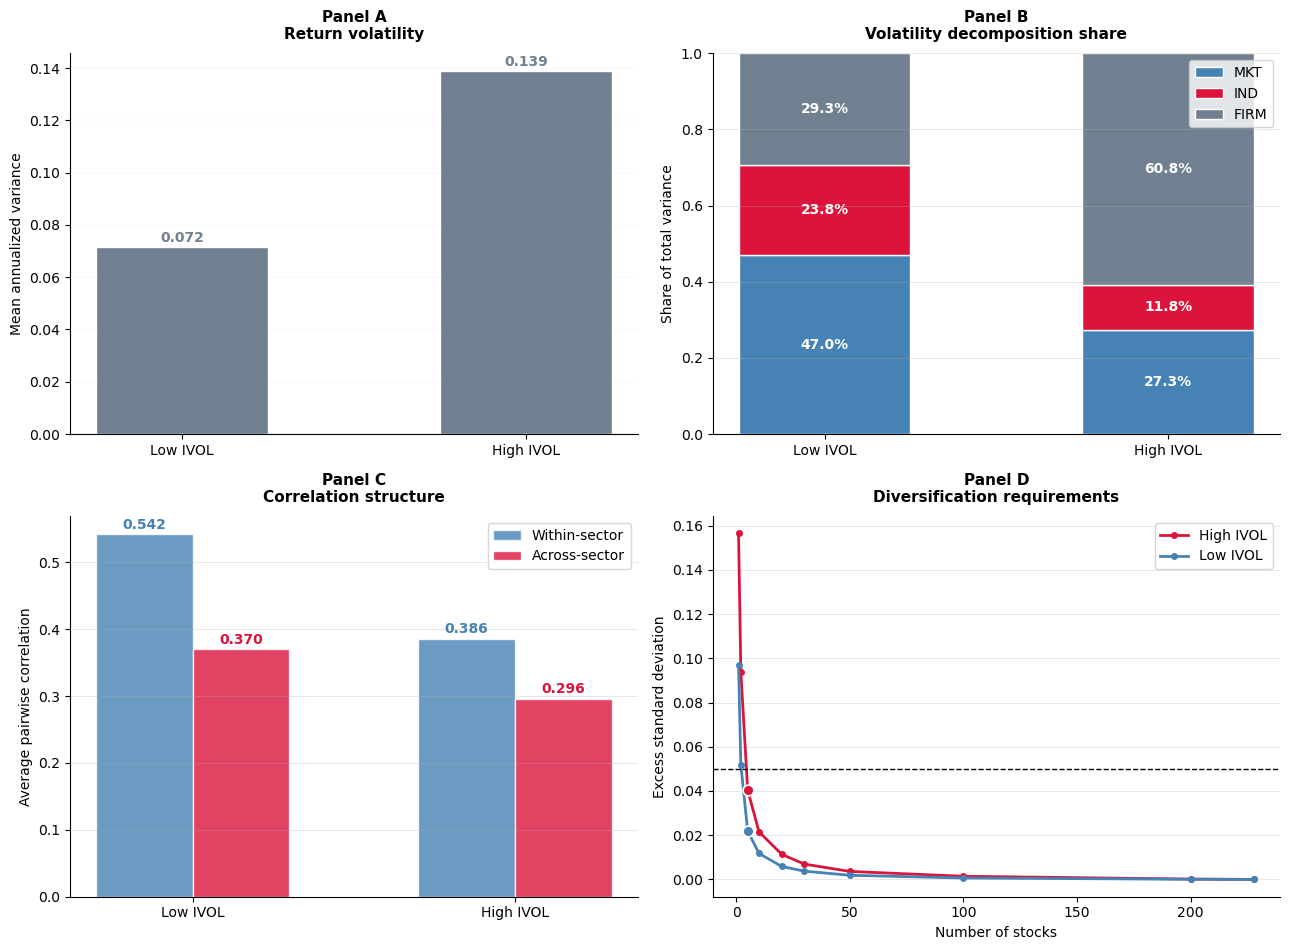

Saved: ivol_comparison_bars.png


In [147]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

groups = ["Low IVOL", "High IVOL"]
group_colors = {"Low IVOL": "steelblue", "High IVOL": "crimson"}
bar_width = 0.3
thinner_width = 0.50  # Further reduced for a sleeker look in B and C

plt.close("all")
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
ax_a, ax_b, ax_c, ax_d = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

# ---------------------------------------------------------------
# PANEL A (Left as is)
# ---------------------------------------------------------------
x_a = np.arange(len(groups))
vals_a = [mean_var_low, mean_var_high]
ax_a.bar(x_a, vals_a, thinner_width, color="slategray", edgecolor="white")

for xi, v in enumerate(vals_a):
    ax_a.annotate(f"{v:.3f}", xy=(xi, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color="slategray")

ax_a.set_title("Panel A\nReturn volatility", fontsize=11, fontweight="bold", pad=10)
ax_a.set_ylabel("Mean annualized variance", fontsize=10)
ax_a.set_xticks(x_a)
ax_a.set_xticklabels(groups, fontsize=10)
ax_a.grid(True, axis="y", alpha=0.3, linewidth=0.2)
ax_a.spines["top"].set_visible(False); ax_a.spines["right"].set_visible(False)
# ---------------------------------------------------------------
# PANEL B (Thinner bars)
# ---------------------------------------------------------------
components = ["MKT", "IND", "FIRM"]
component_colors = {"MKT": "#4682B4", "IND": "#DC143C", "FIRM": "slategray"}
x_b = np.arange(len(groups))
bottoms = np.zeros(len(groups))
shares_by_group = {"Low IVOL": shares_low, "High IVOL": shares_high}

for comp in components:
    vals = [shares_by_group[g][comp] for g in groups]
    ax_b.bar(x_b, vals,thinner_width, bottom=bottoms, color=component_colors[comp], edgecolor="white", label=comp)
    for xi, (v, b) in enumerate(zip(vals, bottoms)):
        if v > 0.03:
            ax_b.annotate(f"{v:.1%}", xy=(xi, b + v / 2), ha="center", va="center", fontsize=10, fontweight="bold", color="white")
    bottoms += np.array(vals)

ax_b.set_title("Panel B\nVolatility decomposition share", fontsize=11, fontweight="bold", pad=10)
ax_b.set_ylabel("Share of total variance", fontsize=10)
ax_b.set_xticks(x_b)
ax_b.set_xticklabels(groups, fontsize=10)
ax_b.set_ylim(0, 1.0)
ax_b.grid(True, axis="y", alpha=0.3, linewidth=0.7)
ax_b.spines["top"].set_visible(False); ax_b.spines["right"].set_visible(False)
ax_b.legend(fontsize=10, loc="upper right")

# ---------------------------------------------------------------
# PANEL C (Thinner bars)
# ---------------------------------------------------------------
within_vals = [within_low, within_high]
across_vals = [across_low, across_high]
x_c = np.arange(len(groups))

ax_c.bar(x_c - bar_width / 2, within_vals, bar_width, color="#4682B4", label="Within-sector", edgecolor="white", alpha=0.8)
ax_c.bar(x_c + bar_width / 2, across_vals, bar_width, color="#DC143C", label="Across-sector", edgecolor="white", alpha=0.8)

for xi, (wv, av) in enumerate(zip(within_vals, across_vals)):
    ax_c.annotate(f"{wv:.3f}", xy=(xi - bar_width / 2, wv), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color="#4682B4")
    ax_c.annotate(f"{av:.3f}", xy=(xi + bar_width / 2, av), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color="#DC143C")

ax_c.set_title("Panel C\nCorrelation structure", fontsize=11, fontweight="bold", pad=10)
ax_c.set_ylabel("Average pairwise correlation", fontsize=10)
ax_c.set_xticks(x_c)
ax_c.set_xticklabels(groups, fontsize=10)
ax_c.grid(True, axis="y", alpha=0.3, linewidth=0.7)
ax_c.spines["top"].set_visible(False); ax_c.spines["right"].set_visible(False)
ax_c.legend(fontsize=10, loc="upper right", framealpha=0.9, edgecolor="lightgray")

# ---------------------------------------------------------------
# PANEL D
# Diversification curve
# ---------------------------------------------------------------

ax_d.plot(
    div_high.index,
    div_high.values,
    color="crimson",
    linewidth=2,
    marker="o",
    markersize=4,
    label="High IVOL"
)

ax_d.plot(
    div_low.index,
    div_low.values,
    color="steelblue",
    linewidth=2,
    marker="o",
    markersize=4,
    label="Low IVOL"
)

# 5% threshold
ax_d.axhline(
    0.05,
    color="black",
    linestyle="--",
    linewidth=1
)

# Highlight threshold portfolios
ax_d.scatter(
    n_needed_high,
    div_high.loc[n_needed_high],
    color="crimson",
    s=60,
    edgecolors="white",
    linewidth=1.2,
    zorder=5
)

ax_d.scatter(
    n_needed_low,
    div_low.loc[n_needed_low],
    color="steelblue",
    s=60,
    edgecolors="white",
    linewidth=1.2,
    zorder=5
)

# Labels

ax_d.set_title(
    "Panel D\nDiversification requirements",
    fontsize=11,
    fontweight="bold",
    pad=10
)

ax_d.set_xlabel("Number of stocks")
ax_d.set_ylabel("Excess standard deviation")

ax_d.grid(True, axis="y", alpha=0.3, linewidth=0.7)

ax_d.spines["top"].set_visible(False)
ax_d.spines["right"].set_visible(False)

ax_d.legend(
    fontsize=10,
    loc="upper right",
    framealpha=0.9,
    edgecolor="lightgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("ivol_comparison_bars.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: ivol_comparison_bars.png")

In [66]:
plt.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    "ivol_comparison_panels.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [67]:
# Calculate the full correlation matrix
full_corr_matrix = excess_rets.corr()

# Create a mask for same-sector pairs
# Ensure your sector_map is aligned with the columns of excess_rets
aligned_sector_map = sector_map.reindex(excess_rets.columns)
same_sector_mask = aligned_sector_map.values[:, None] == aligned_sector_map.values[None, :]

# Create a mask for the upper triangle (to avoid diagonal 1s and duplicates)
upper_tri_mask = np.triu(np.ones(full_corr_matrix.shape), k=1).astype(bool)

# Filter for same-sector correlations
within_corr_all = full_corr_matrix.values[same_sector_mask & upper_tri_mask].mean()

# Filter for across-sector correlations
across_corr_all = full_corr_matrix.values[~same_sector_mask & upper_tri_mask].mean()

print(f"Whole Sample Within-sector Correlation: {within_corr_all:.4f}")
print(f"Whole Sample Across-sector Correlation: {across_corr_all:.4f}")

Whole Sample Within-sector Correlation: 0.4475
Whole Sample Across-sector Correlation: 0.3221
